# 📰 Fake News Detector — Exploratory Data Analysis (EDA)

Analisis dataset **40.000+ artikel berita Real vs Fake** (GonzaloA/fake_news, Hugging Face).

**Isi analisis:**
1. Gambaran umum dataset & distribusi kelas
2. Audit kebocoran data (shortcut "Reuters")
3. Distribusi panjang teks
4. Kata-kata paling sering muncul pada berita Fake vs Real
5. Word Cloud per kelas
6. Evaluasi model **leakage-free**: Confusion Matrix, ROC-AUC, threshold tuning


In [1]:
import os
import sys
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, accuracy_score, f1_score
import joblib

# Arahkan working directory ke root project
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)

print('Project root:', ROOT)

Project root: /home/ayubw/projects/fake-news-detector


## 1. Dataset Overview

Dataset lengkap disiapkan oleh `scripts/prepare_dataset.py`: 40.587 artikel digabung, dideduplikasi, label dinormalisasi (0 = Real, 1 = Fake), dan shortcut agensi berita dihapus.

In [2]:
from train_model import load_dataset, clean_text

df, source = load_dataset()
print(f'Source     : {source}')
print(f'Total rows : {len(df):,}')
print(f'Columns    : {list(df.columns)}')
df[['text', 'label']].head(3)

Loaded dataset from: /home/ayubw/projects/fake-news-detector/data/train.csv


Merged 11 human-feedback samples from: /home/ayubw/projects/fake-news-detector/data/feedback.csv
Source     : /home/ayubw/projects/fake-news-detector/data/train.csv
Total rows : 40,455
Columns    : ['text', 'label', 'clean_text']


,text,label
0,Trump lawyers aim to delay fraud trial at hear...,0
1,4 DEAD TEENAGERS In Two Weeks…Illegal Immigran...,1
2,Obama meets with national security team on Syr...,0


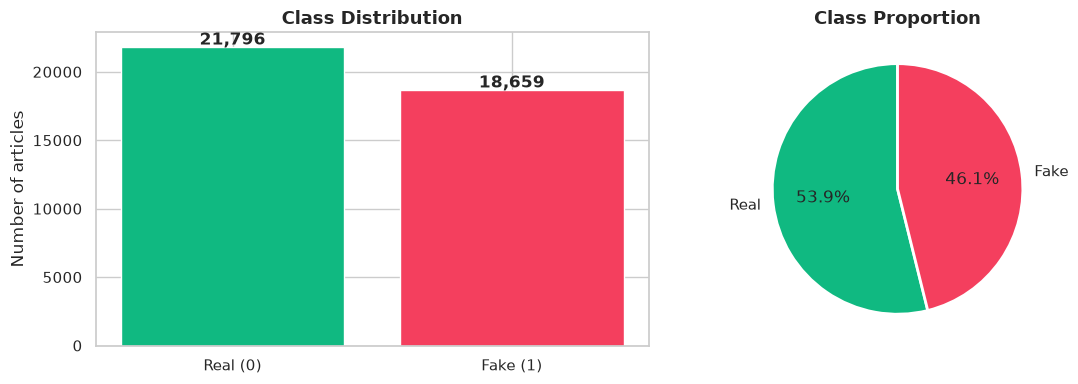

Imbalance ratio: 1.17 : 1


In [3]:
class_counts = df['label'].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

bars = axes[0].bar(['Real (0)', 'Fake (1)'], class_counts.values,
                   color=['#10b981', '#f43f5e'])
axes[0].set_title('Class Distribution', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Number of articles')
for bar, val in zip(bars, class_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, val + 200, f'{val:,}',
                 ha='center', fontweight='bold')

axes[1].pie(class_counts.values, labels=['Real', 'Fake'], autopct='%1.1f%%',
            colors=['#10b981', '#f43f5e'], startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Class Proportion', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

print(f'Imbalance ratio: {class_counts.max() / class_counts.min():.2f} : 1')

## 2. Audit Kebocoran Data — Shortcut "Reuters"

Temuan penting: pada dataset mentah, **96.5% artikel Real** menyebut "Reuters", sedangkan hanya **1.3% artikel Fake**. Model yang naif akan menghafal kata "Reuters" alih-alih memahami konten (*shortcut learning*).

Karena itu, `prepare_dataset.py` menghapus marker agensi. Audit di bawah membandingkan sebelum vs sesudah.

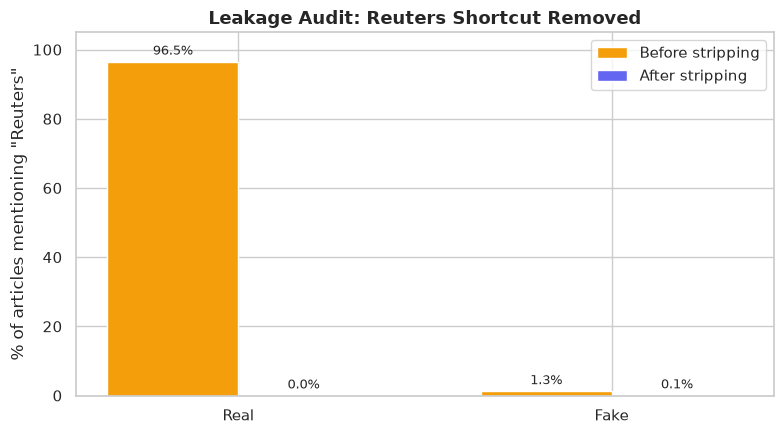

Leakage shortcut berhasil dihilangkan: dari ~96% menjadi ~0%.
Reuters share sekarang: 0.05%


In [4]:
raw_path = Path('data/raw_train.csv')
if raw_path.exists():
    raw = pd.read_csv(raw_path, sep=';')
    raw['label_fake'] = 1 - raw['label']  # 1=true -> fake=0

    before = raw.groupby('label_fake')['text'].apply(
        lambda s: s.str.contains('Reuters', case=False, na=False).mean() * 100
    )
    after = df.groupby('label')['clean_text'].apply(
        lambda s: s.str.contains('reuters', case=False, na=False).mean() * 100
    )

    labels = ['Real', 'Fake']
    x = np.arange(2)
    width = 0.35

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.bar(x - width/2, [before.get(0, 0), before.get(1, 0)], width,
           label='Before stripping', color='#f59e0b')
    ax.bar(x + width/2, [after.get(0, 0), after.get(1, 0)], width,
           label='After stripping', color='#6366f1')
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylabel('% of articles mentioning "Reuters"')
    ax.set_title('Leakage Audit: Reuters Shortcut Removed', fontsize=13, fontweight='bold')
    ax.legend()
    ax.set_ylim(0, 105)

    for i, v in enumerate([before.get(0, 0), before.get(1, 0)]):
        ax.text(i - width/2, v + 2, f'{v:.1f}%', ha='center', fontsize=9)
    for i, v in enumerate([after.get(0, 0), after.get(1, 0)]):
        ax.text(i + width/2, v + 2, f'{v:.1f}%', ha='center', fontsize=9)

    plt.tight_layout()
    plt.show()
    print('Leakage shortcut berhasil dihilangkan: dari ~96% menjadi ~0%.')
else:
    print('Raw dataset tidak ditemukan — jalankan scripts/prepare_dataset.py untuk audit lengkap.')

print('Reuters share sekarang:', f"{df['clean_text'].str.contains('reuters').mean()*100:.2f}%")

## 3. Text Length Distribution

/tmp/ipykernel_17756/2902470144.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(['Real', 'Fake'])


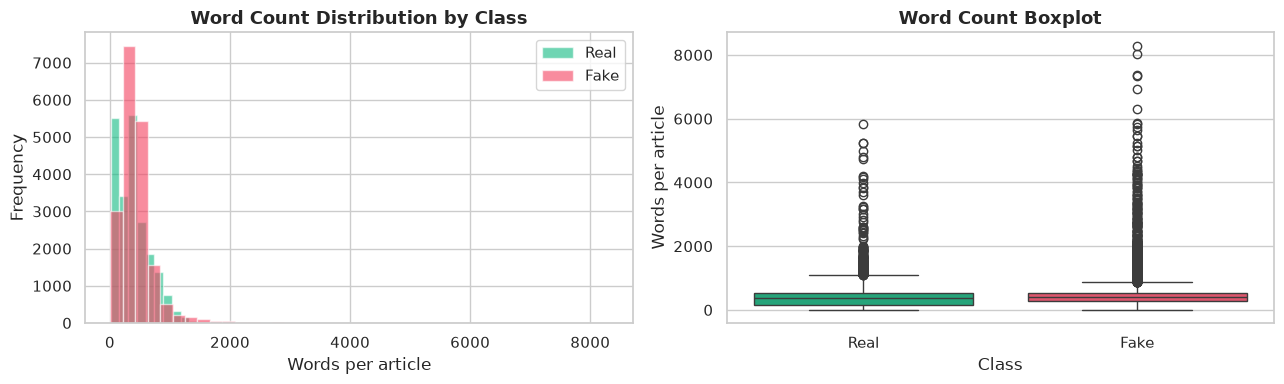

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,21796.0,401.3,303.0,11.0,154.0,368.0,536.0,5839.0
1,18659.0,450.4,382.0,6.0,289.0,395.0,528.0,8294.0


In [5]:
df['word_count'] = df['clean_text'].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for label, color, name in [(0, '#10b981', 'Real'), (1, '#f43f5e', 'Fake')]:
    subset = df[df['label'] == label]['word_count']
    axes[0].hist(subset, bins=40, alpha=0.6, color=color, label=name)
axes[0].set_title('Word Count Distribution by Class', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Words per article')
axes[0].set_ylabel('Frequency')
axes[0].legend()

sns.boxplot(data=df, x='label', y='word_count', hue='label',
            palette=['#10b981', '#f43f5e'], legend=False, ax=axes[1])
axes[1].set_xticklabels(['Real', 'Fake'])
axes[1].set_title('Word Count Boxplot', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Words per article')

plt.tight_layout()
plt.show()

df.groupby('label')['word_count'].describe().round(1)

## 4. Top Words — Fake vs Real

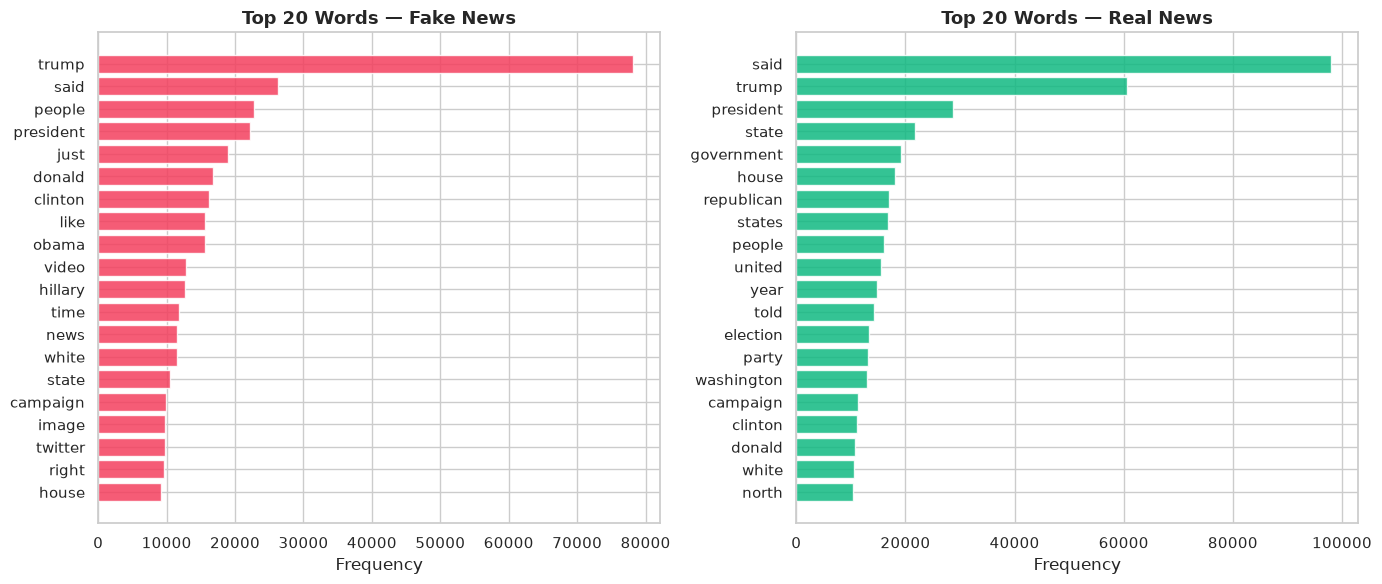

In [6]:
from collections import Counter
from sklearn.feature_extraction.text import TfidfVectorizer

STOPWORDS = set(TfidfVectorizer(stop_words='english').get_stop_words())

def top_words(texts, n=20):
    counter = Counter()
    for text in texts:
        words = [w for w in text.split() if w not in STOPWORDS and len(w) > 3]
        counter.update(words)
    return counter.most_common(n)

fake_top = top_words(df[df['label'] == 1]['clean_text'])
real_top = top_words(df[df['label'] == 0]['clean_text'])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, data, color, name in [
    (axes[0], fake_top, '#f43f5e', 'Fake News'),
    (axes[1], real_top, '#10b981', 'Real News')
]:
    words, counts = zip(*data)
    ax.barh(list(words)[::-1], list(counts)[::-1], color=color, alpha=0.85)
    ax.set_title(f'Top 20 Words — {name}', fontsize=13, fontweight='bold')
    ax.set_xlabel('Frequency')

plt.tight_layout()
plt.show()

## 5. Word Clouds per Class

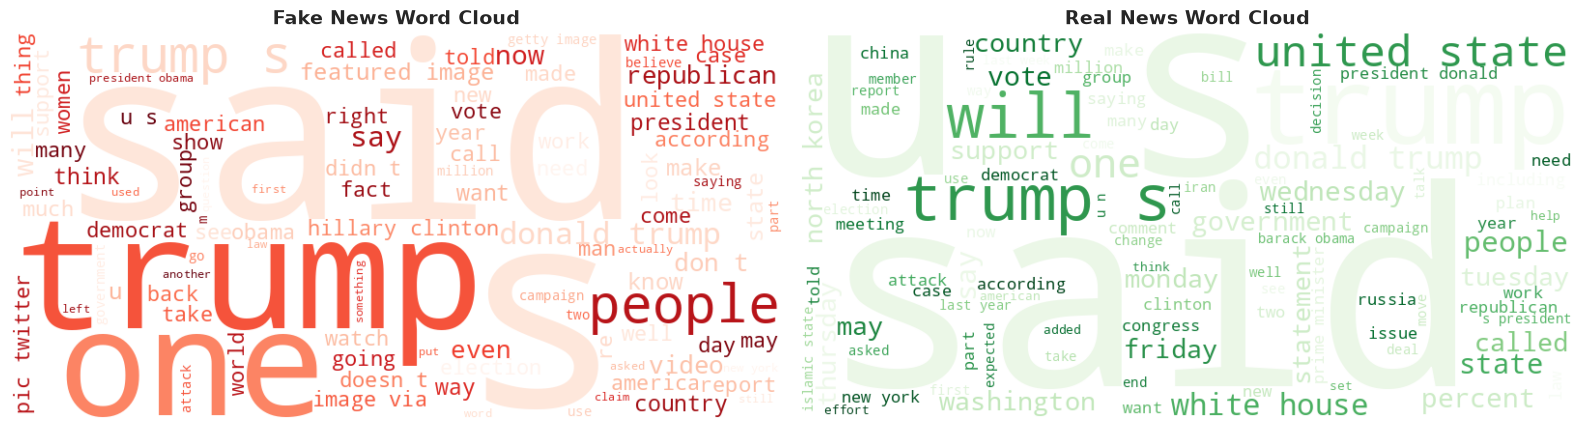

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, label, colormap, title in [
    (axes[0], 1, 'Reds', 'Fake News Word Cloud'),
    (axes[1], 0, 'Greens', 'Real News Word Cloud')
]:
    text_blob = ' '.join(df[df['label'] == label]['clean_text'].sample(
        n=min(15000, (df['label'] == label).sum()), random_state=42))
    wc = WordCloud(width=800, height=400, background_color='white',
                   colormap=colormap, max_words=100, random_state=42).generate(text_blob)
    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.show()

## 6. Model Evaluation — Leakage-Free Test Set

Model terlatih dievaluasi pada **20% test set yang tidak pernah dilihat** saat training. TF-IDF dan SMOTETomek hanya diterapkan pada training set (lihat `train_model.py`).

In [8]:
import json

# Recreate the exact same stratified split used in training
train_df, test_df = train_test_split(
    df, test_size=0.20, random_state=42, stratify=df['label']
)

tfidf = joblib.load('models/vectorizer.pkl')
model = joblib.load('models/model.pkl')

with open('models/threshold.json') as f:
    threshold = json.load(f)['threshold']

X_test = tfidf.transform(test_df['clean_text'])
y_test = test_df['label'].values
proba = model.predict_proba(X_test)[:, 1]
y_pred = (proba >= threshold).astype(int)

print(f'Test samples : {len(test_df):,}')
print(f'Threshold    : {threshold:.2f}')
print(f'Accuracy     : {accuracy_score(y_test, y_pred):.2%}')
print(f'Fake F1      : {f1_score(y_test, y_pred, pos_label=1):.4f}')
print(f'ROC-AUC      : {roc_auc_score(y_test, proba):.4f}')

Test samples : 8,091
Threshold    : 0.44
Accuracy     : 97.52%
Fake F1      : 0.9732
ROC-AUC      : 0.9948


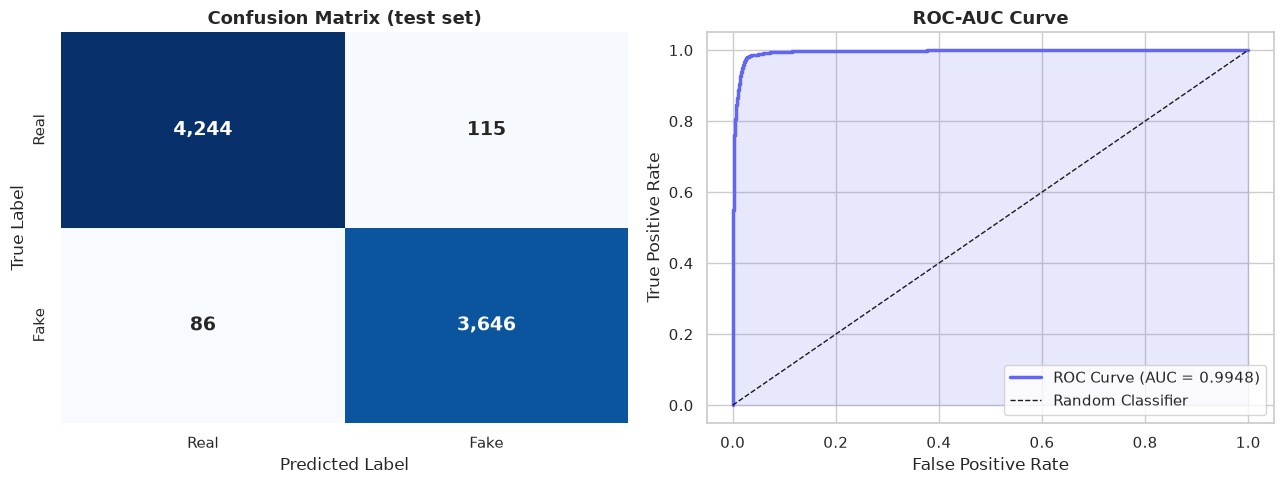

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False,
            xticklabels=['Real', 'Fake'], yticklabels=['Real', 'Fake'],
            annot_kws={'size': 14, 'fontweight': 'bold'}, ax=axes[0])
axes[0].set_title('Confusion Matrix (test set)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

fpr, tpr, _ = roc_curve(y_test, proba)
auc = roc_auc_score(y_test, proba)
axes[1].plot(fpr, tpr, color='#6366f1', lw=2.5, label=f'ROC Curve (AUC = {auc:.4f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1, label='Random Classifier')
axes[1].fill_between(fpr, tpr, alpha=0.15, color='#6366f1')
axes[1].set_title('ROC-AUC Curve', fontsize=13, fontweight='bold')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

## 7. Key Takeaways

| Aspek | Temuan |
|-------|--------|
| **Skala dataset** | 40.449 artikel setelah deduplikasi (Real 21.790 / Fake 18.659). |
| **Leakage** | Shortcut "Reuters" (96.5% pada Real) dihapus → model belajar konten, bukan nama agensi. |
| **Metodologi** | Split → fit TF-IDF (train only) → SMOTE (train only) → evaluate di test set murni. |
| **Threshold** | 0.44 dipilih dari validation split untuk memaksimalkan F1 kelas Fake. |
| **Performa** | Accuracy ~97.5%, ROC-AUC ~0.995, Fake F1 ~0.97 — hasil jujur tanpa kebocoran data. |
| **Perbandingan model** | LinearSVC (F1 0.961) > LogisticRegression (0.955) > Naive Bayes (0.920). |

**Batasan yang perlu disebutkan di portofolio:**
- Dataset berbahasa Inggris; untuk berita Indonesia perlu dataset lokal / IndoBERT.
- TF-IDF menangkap pola kata, bukan penalaran semantik mendalam.
- Distribusi berita dunia nyata berbeda — evaluasi berkala dan feedback loop tetap diperlukan.